In [1]:
# 1. УСТАНОВКА БИБЛИОТЕК
!pip install transformers torch scikit-learn pandas numpy matplotlib seaborn pymorphy3 gensim -q

import warnings
warnings.filterwarnings('ignore')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Проверка GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🔧 Устройство: {device}")
if torch.cuda.is_available():
    print(f"🎮 GPU: {torch.cuda.get_device_name(0)}")

🔧 Устройство: cuda
🎮 GPU: Tesla T4


In [2]:
# 2. ЗАГРУЗКА ДАННЫХ
print("\n📂 Загрузи 4 файла: reviews.csv, reviews_clean.csv, train.csv, test.csv")
uploaded = files.upload()

for fname in ['reviews.csv', 'reviews_clean.csv', 'train.csv', 'test.csv']:
    if fname in uploaded:
        print(f"✅ {fname} загружен")
    else:
        print(f"❌ {fname} НЕ найден")

# Загрузка
train = pd.read_csv('train.csv', encoding='utf-8')
test = pd.read_csv('test.csv', encoding='utf-8')

LABEL_COLS = [
    'Большой бар', 'День рождения', 'Добавить мистики', 'Здоровое меню',
    'Красивый вид', 'Кухни мира', 'Необычные вкусы', 'Поболтать',
    'Покормить детей', 'Поработать', 'Потусить', 'Праздник',
    'Просто поесть', 'Просторный зал', 'Расслабиться', 'Свидание',
    'Стильный интерьер', 'Удобные сиденья', 'Фоткаться'
]

print(f"\n📊 Train: {len(train)} отзывов, Test: {len(test)} отзывов")
print(f"🏷️  Характеристики: {len(LABEL_COLS)}")


📂 Загрузи 4 файла: reviews.csv, reviews_clean.csv, train.csv, test.csv


Saving predictions.csv to predictions.csv
Saving reviews.csv to reviews.csv
Saving reviews_clean.csv to reviews_clean.csv
Saving task_2_vibes.json to task_2_vibes.json
Saving test.csv to test.csv
Saving train.csv to train.csv
✅ reviews.csv загружен
✅ reviews_clean.csv загружен
✅ train.csv загружен
✅ test.csv загружен

📊 Train: 100229 отзывов, Test: 25057 отзывов
🏷️  Характеристики: 19



📈 РАЗВЕДОЧНЫЙ АНАЛИЗ

Распределение классов (% положительных):
  Просто поесть: 46.7%
  Удобные сиденья: 29.5%
  Стильный интерьер: 12.5%
  Расслабиться: 12.1%
  Необычные вкусы: 11.2%
  Потусить: 7.3%
  Большой бар: 5.5%
  Фоткаться: 5.5%
  Здоровое меню: 5.2%
  Покормить детей: 4.9%
  Кухни мира: 4.4%
  Поболтать: 4.2%
  Праздник: 4.0%
  Красивый вид: 3.0%
  Поработать: 1.8%
  Просторный зал: 1.7%
  Свидание: 1.5%
  Добавить мистики: 0.8%
  День рождения: 0.7%


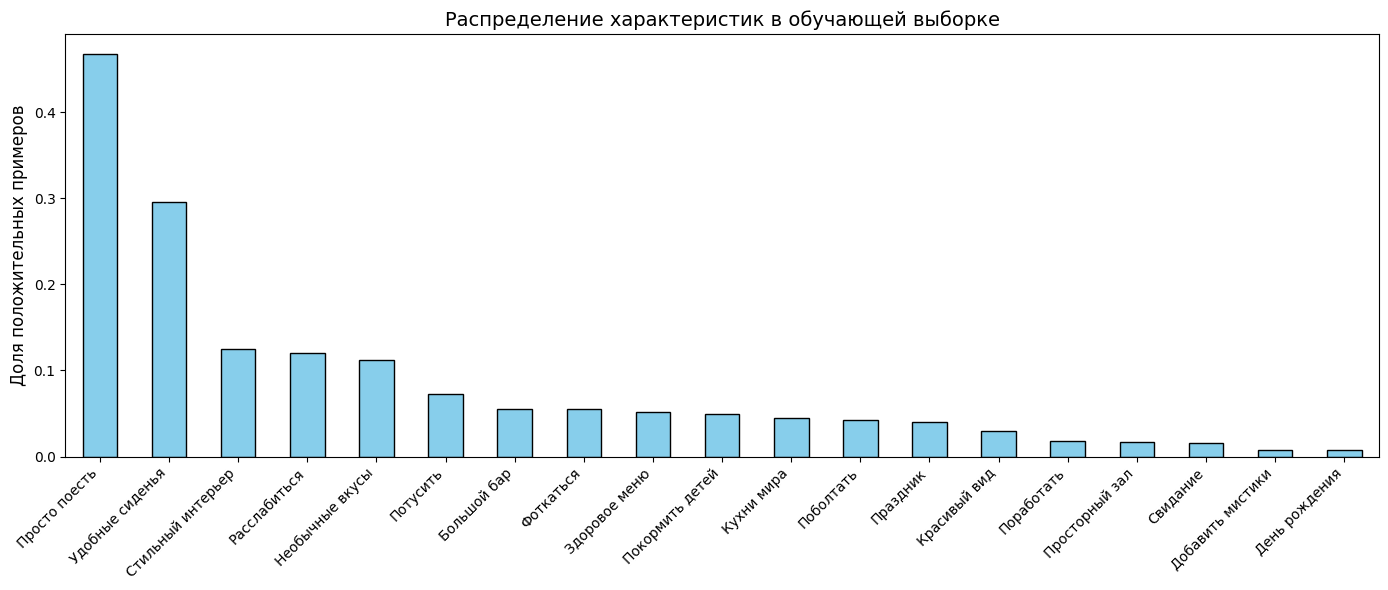


📏 Статистика длины текстов:
  Train: средняя=184, медиана=141
  Test:  средняя=184, медиана=142


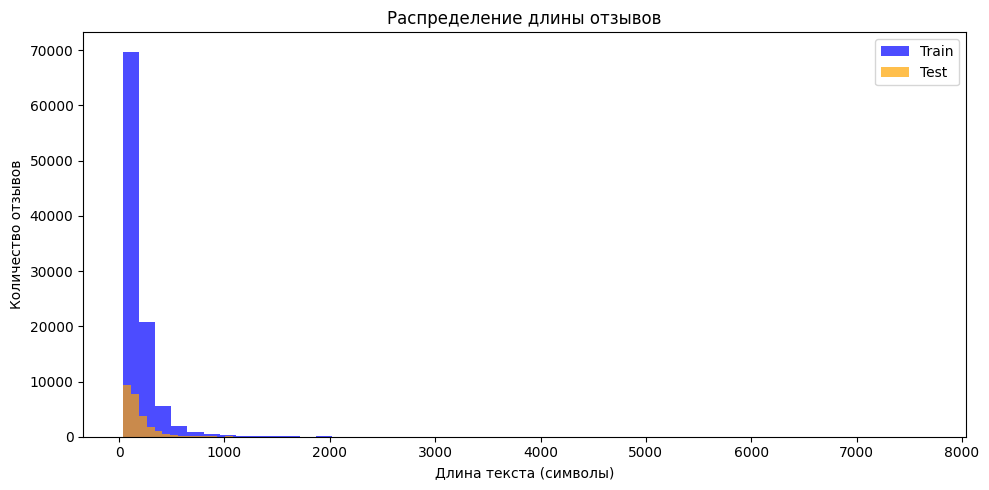

In [3]:
# 3. РАЗВЕДОЧНЫЙ АНАЛИЗ (EDA)
print("\n" + "="*70)
print("📈 РАЗВЕДОЧНЫЙ АНАЛИЗ")
print("="*70)

# Распределение классов
class_dist = train[LABEL_COLS].mean().sort_values(ascending=False)
print("\nРаспределение классов (% положительных):")
for col, pct in class_dist.items():
    print(f"  {col}: {pct*100:.1f}%")

# Визуализация распределения
plt.figure(figsize=(14, 6))
class_dist.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Распределение характеристик в обучающей выборке', fontsize=14)
plt.ylabel('Доля положительных примеров', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# Длина текстов
train['text_length'] = train['text'].str.len()
test['text_length'] = test['text'].str.len()

print(f"\n📏 Статистика длины текстов:")
print(f"  Train: средняя={train['text_length'].mean():.0f}, медиана={train['text_length'].median():.0f}")
print(f"  Test:  средняя={test['text_length'].mean():.0f}, медиана={test['text_length'].median():.0f}")

plt.figure(figsize=(10, 5))
plt.hist(train['text_length'], bins=50, alpha=0.7, label='Train', color='blue')
plt.hist(test['text_length'], bins=50, alpha=0.7, label='Test', color='orange')
plt.xlabel('Длина текста (символы)')
plt.ylabel('Количество отзывов')
plt.title('Распределение длины отзывов')
plt.legend()
plt.tight_layout()
plt.savefig('text_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# 4. ПРЕДОБРАБОТКА ТЕКСТА (ЛЕММАТИЗАЦИЯ)
print("\n" + "="*70)
print("🔤 ПРЕДОБРАБОТКА ТЕКСТА")
print("="*70)

import pymorphy3
import re

morph = pymorphy3.MorphAnalyzer()

# Стоп-слова (оставляем "не" и "нет")
STOP_POS = {'PREP', 'PRCL', 'CONJ', 'NPRO', 'INTJ'}  # предлоги, частицы (кроме НЕ), союзы, местоимения, междометия

def preprocess_text(text):
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'[^а-яёa-z\s]', ' ', text)  # оставляем только буквы
    words = text.split()
    lemmas = []
    for word in words:
        parsed = morph.parse(word)[0]
        if parsed.tag.POS not in STOP_POS and word not in {'не', 'нет'}:
            lemmas.append(parsed.normal_form)
        elif word in {'не', 'нет'}:
            lemmas.append(word)
    return ' '.join(lemmas)

print("Лемматизирую тексты (может занять 2-3 минуты)...")
train['text_clean'] = train['text'].apply(preprocess_text)
test['text_clean'] = test['text'].apply(preprocess_text)

print(f"✅ Предобработка завершена")
print(f"  Пример: '{train['text'].iloc[0][:80]}...'")
print(f"  → '{train['text_clean'].iloc[0][:80]}...'")


🔤 ПРЕДОБРАБОТКА ТЕКСТА
Лемматизирую тексты (может занять 2-3 минуты)...
✅ Предобработка завершена
  Пример: 'Были тут на выходных, и я просто в восторге от их авторских конфет ручной работы...'
  → 'быть тут выходной восторг авторский конфета ручной работа каждый топ надолго зап...'


In [5]:
# 5. МОДЕЛЬ 1: TF-IDF + LOGISTIC REGRESSION
print("\n" + "="*70)
print("🚀 МОДЕЛЬ 1: TF-IDF + LogisticRegression")
print("="*70)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score, average_precision_score
import joblib

# Подготовка
X_train_text = train['text_clean'].fillna('')
y_train = train[LABEL_COLS].values
X_test_text = test['text_clean'].fillna('')
y_test = test[LABEL_COLS].values

# TF-IDF
vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=3,
    max_df=0.95
)

X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# Классификатор (сбалансированный)
classifier = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced', solver='lbfgs')
)

print("Обучаю модель...")
classifier.fit(X_train_tfidf, y_train)

# Предсказания
y_pred_tfidf = classifier.predict(X_test_tfidf)
y_proba_tfidf = classifier.predict_proba(X_test_tfidf)

# Метрики
f1_macro_tfidf = f1_score(y_test, y_pred_tfidf, average='macro', zero_division=0)
f1_per_class_tfidf = f1_score(y_test, y_pred_tfidf, average=None, zero_division=0)

pr_auc_tfidf = []
for i in range(len(LABEL_COLS)):
    if y_test[:, i].sum() > 0:
        auc = average_precision_score(y_test[:, i], y_proba_tfidf[:, i])
    else:
        auc = 0.0
    pr_auc_tfidf.append(auc)

print(f"\n✅ TF-IDF модель обучена!")
print(f"   F1-macro: {f1_macro_tfidf:.4f}")
print(f"   PR-AUC (mean): {np.mean(pr_auc_tfidf):.4f}")


🚀 МОДЕЛЬ 1: TF-IDF + LogisticRegression
Обучаю модель...

✅ TF-IDF модель обучена!
   F1-macro: 0.4857
   PR-AUC (mean): 0.5169


In [6]:
# 5. МОДЕЛЬ 1: TF-IDF + LOGISTIC REGRESSION
print("\n" + "="*70)
print("🚀 МОДЕЛЬ 1: TF-IDF + LogisticRegression")
print("="*70)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score, average_precision_score
import joblib

# Подготовка
X_train_text = train['text_clean'].fillna('')
y_train = train[LABEL_COLS].values
X_test_text = test['text_clean'].fillna('')
y_test = test[LABEL_COLS].values

# TF-IDF
vectorizer = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=3,
    max_df=0.95
)

X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# Классификатор (сбалансированный)
classifier = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced', solver='lbfgs')
)

print("Обучаю модель...")
classifier.fit(X_train_tfidf, y_train)

# Предсказания
y_pred_tfidf = classifier.predict(X_test_tfidf)
y_proba_tfidf = classifier.predict_proba(X_test_tfidf)

# Метрики
f1_macro_tfidf = f1_score(y_test, y_pred_tfidf, average='macro', zero_division=0)
f1_per_class_tfidf = f1_score(y_test, y_pred_tfidf, average=None, zero_division=0)

pr_auc_tfidf = []
for i in range(len(LABEL_COLS)):
    if y_test[:, i].sum() > 0:
        auc = average_precision_score(y_test[:, i], y_proba_tfidf[:, i])
    else:
        auc = 0.0
    pr_auc_tfidf.append(auc)

print(f"\n✅ TF-IDF модель обучена!")
print(f"   F1-macro: {f1_macro_tfidf:.4f}")
print(f"   PR-AUC (mean): {np.mean(pr_auc_tfidf):.4f}")


🚀 МОДЕЛЬ 1: TF-IDF + LogisticRegression
Обучаю модель...

✅ TF-IDF модель обучена!
   F1-macro: 0.4857
   PR-AUC (mean): 0.5169


In [7]:
# 6. МОДЕЛЬ 2: WORD2VEC + LOGISTIC REGRESSION
print("\n" + "="*70)
print("🚀 МОДЕЛЬ 2: Word2Vec + LogisticRegression")
print("="*70)

from gensim.models import Word2Vec

# Обучение Word2Vec
print("Обучаю Word2Vec...")
sentences = [text.split() for text in X_train_text if text]

w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=3,
    workers=4,
    epochs=10
)

print(f"✅ Word2Vec обучен. Словарь: {len(w2v_model.wv)} слов")

# Векторизация текстов
def text_to_vector(text, model, vector_size=100):
    words = text.split()
    word_vectors = [model.wv[word] for word in words if word in model.wv]
    if len(word_vectors) == 0:
        return np.zeros(vector_size)
    return np.mean(word_vectors, axis=0)

print("Векторизую тексты...")
X_train_w2v = np.array([text_to_vector(text, w2v_model) for text in X_train_text])
X_test_w2v = np.array([text_to_vector(text, w2v_model) for text in X_test_text])

# Классификатор
w2v_classifier = OneVsRestClassifier(
    LogisticRegression(max_iter=1000, C=1.0, class_weight='balanced', solver='lbfgs')
)

print("Обучаю модель...")
w2v_classifier.fit(X_train_w2v, y_train)

# Предсказания
y_pred_w2v = w2v_classifier.predict(X_test_w2v)
y_proba_w2v = w2v_classifier.predict_proba(X_test_w2v)

# Метрики
f1_macro_w2v = f1_score(y_test, y_pred_w2v, average='macro', zero_division=0)
f1_per_class_w2v = f1_score(y_test, y_pred_w2v, average=None, zero_division=0)

pr_auc_w2v = []
for i in range(len(LABEL_COLS)):
    if y_test[:, i].sum() > 0:
        auc = average_precision_score(y_test[:, i], y_proba_w2v[:, i])
    else:
        auc = 0.0
    pr_auc_w2v.append(auc)

print(f"\n✅ Word2Vec модель обучена!")
print(f"   F1-macro: {f1_macro_w2v:.4f}")
print(f"   PR-AUC (mean): {np.mean(pr_auc_w2v):.4f}")


🚀 МОДЕЛЬ 2: Word2Vec + LogisticRegression
Обучаю Word2Vec...
✅ Word2Vec обучен. Словарь: 15578 слов
Векторизую тексты...
Обучаю модель...

✅ Word2Vec модель обучена!
   F1-macro: 0.3138
   PR-AUC (mean): 0.3593


In [8]:
# 7. МОДЕЛЬ 3: BERT (ruBERT)
print("\n" + "="*70)
print("🚀 МОДЕЛЬ 3: BERT (DeepPavlov/rubert-base-cased)")
print("="*70)

from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split

MODEL_NAME = 'DeepPavlov/rubert-base-cased'
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
LR = 2e-5

print(f"Загружаю модель: {MODEL_NAME}")

# Делим train на train/val
train_split, val_split = train_test_split(
    train, test_size=0.1, random_state=42,
    stratify=train[LABEL_COLS].sum(axis=1) > 0
)

print(f"Train: {len(train_split)}, Val: {len(val_split)}, Test: {len(test)}")

# Dataset
class ReviewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts.tolist()
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.float)
        }

# Загрузка модели
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_COLS),
    problem_type="multi_label_classification"
)
model.config.problem_type = "multi_label_classification"
model.to(device)

# Создание датасетов
train_dataset = ReviewsDataset(train_split['text'], train_split[LABEL_COLS].values, tokenizer, MAX_LENGTH)
val_dataset = ReviewsDataset(val_split['text'], val_split[LABEL_COLS].values, tokenizer, MAX_LENGTH)
test_dataset = ReviewsDataset(test['text'], test[LABEL_COLS].values, tokenizer, MAX_LENGTH)

# Метрики
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = (1 / (1 + np.exp(-logits))) > 0.5
    f1_macro = f1_score(labels, preds, average='macro', zero_division=0)

    pr_aucs = []
    for i in range(labels.shape[1]):
        if labels[:, i].sum() > 0:
            auc = average_precision_score(labels[:, i], logits[:, i])
            pr_aucs.append(auc)

    return {
        'f1_macro': f1_macro,
        'pr_auc_mean': np.mean(pr_aucs) if pr_aucs else 0
    }

# Аргументы обучения
training_args = TrainingArguments(
    output_dir='./bert_results',
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LR,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=50,
    report_to="none",
    fp16=torch.cuda.is_available(),
)

# Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
)

print("\n🚀 Начинаю обучение BERT...")
trainer.train()

# Оценка на тесте
print("\n📊 Оценка на тестовой выборке...")
predictions = trainer.predict(test_dataset)
logits = predictions.predictions
labels = predictions.label_ids
y_pred_bert = (1 / (1 + np.exp(-logits))) > 0.5

# Метрики
f1_macro_bert = f1_score(labels, y_pred_bert, average='macro', zero_division=0)
f1_per_class_bert = f1_score(labels, y_pred_bert, average=None, zero_division=0)

pr_auc_bert = []
for i in range(len(LABEL_COLS)):
    if labels[:, i].sum() > 0:
        auc = average_precision_score(labels[:, i], logits[:, i])
    else:
        auc = 0.0
    pr_auc_bert.append(auc)

print(f"\n✅ BERT модель обучена!")
print(f"   F1-macro: {f1_macro_bert:.4f}")
print(f"   PR-AUC (mean): {np.mean(pr_auc_bert):.4f}")


🚀 МОДЕЛЬ 3: BERT (DeepPavlov/rubert-base-cased)
Загружаю модель: DeepPavlov/rubert-base-cased
Train: 90206, Val: 10023, Test: 25057


config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


📊 Оценка на тестовой выборке...



✅ BERT модель обучена!
   F1-macro: 0.5492
   PR-AUC (mean): 0.5862



📊 СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ

Метрика              TF-IDF          Word2Vec        BERT           
-----------------------------------------------------------------
F1-macro             0.4857          0.3138          0.5492         
PR-AUC (mean)        0.5169          0.3593          0.5862         

Характеристика            TF-IDF F1    W2V F1       BERT F1     
----------------------------------------------------------------------
Большой бар               0.5733       0.4432       0.6634      
День рождения             0.2868       0.1132       0.3292      
Добавить мистики          0.1914       0.0578       0.0000      
Здоровое меню             0.4181       0.2437       0.4702      
Красивый вид              0.6488       0.3613       0.7914      
Кухни мира                0.3614       0.2236       0.4308      
Необычные вкусы           0.3999       0.3483       0.3406      
Поболтать                 0.4661       0.2945       0.5483      
Покормить детей           0.5710       0.32

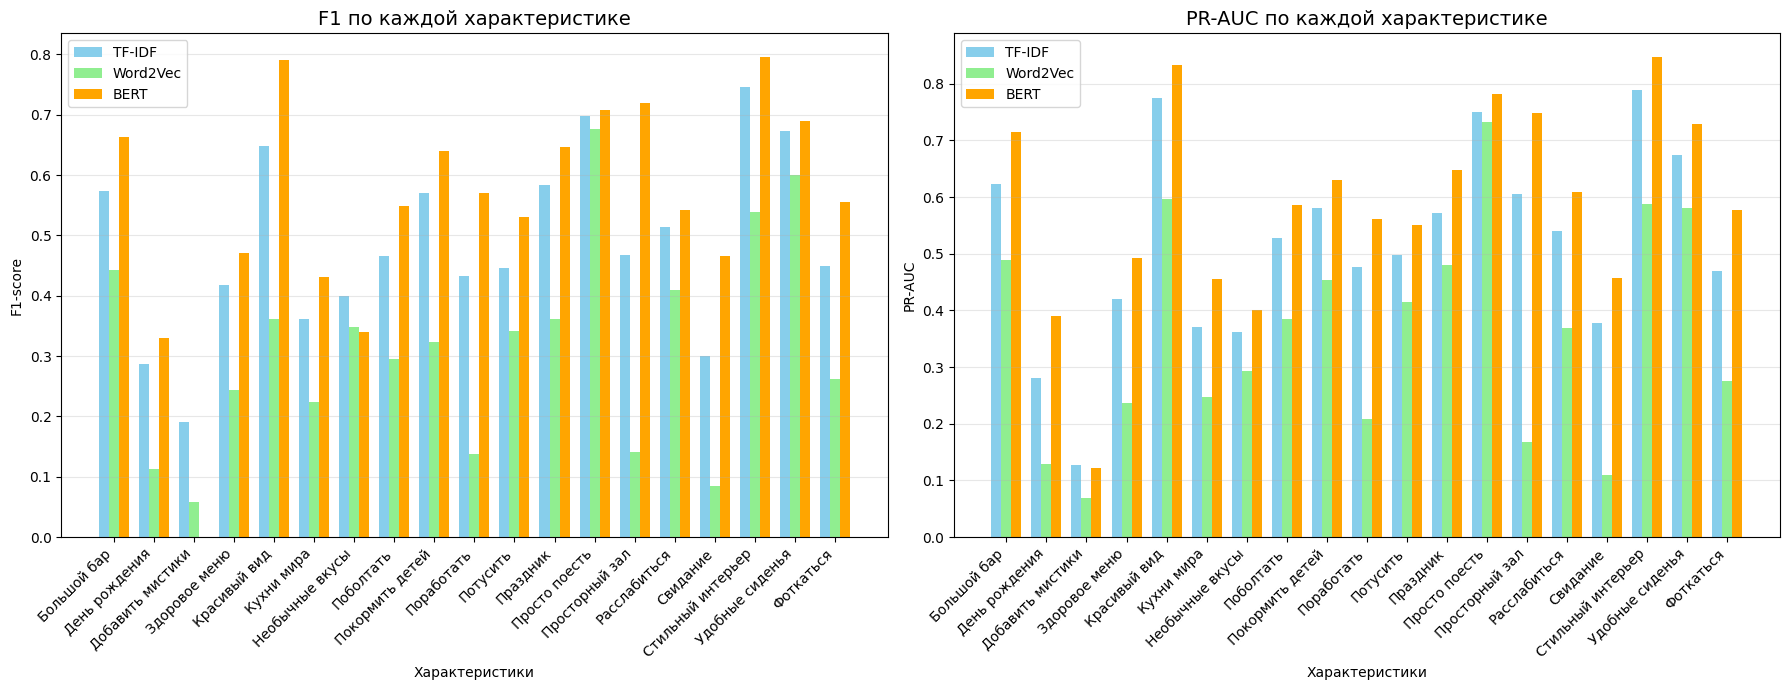


📈 BERT улучшил F1-macro над TF-IDF на 0.0635 (13.1%)
📈 BERT улучшил PR-AUC над TF-IDF на 0.0693


In [9]:
# 8. СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ
print("\n" + "="*70)
print("📊 СРАВНЕНИЕ ВСЕХ МОДЕЛЕЙ")
print("="*70)

print(f"\n{'Метрика':<20} {'TF-IDF':<15} {'Word2Vec':<15} {'BERT':<15}")
print("-" * 65)
print(f"{'F1-macro':<20} {f1_macro_tfidf:<15.4f} {f1_macro_w2v:<15.4f} {f1_macro_bert:<15.4f}")
print(f"{'PR-AUC (mean)':<20} {np.mean(pr_auc_tfidf):<15.4f} {np.mean(pr_auc_w2v):<15.4f} {np.mean(pr_auc_bert):<15.4f}")

print(f"\n{'Характеристика':<25} {'TF-IDF F1':<12} {'W2V F1':<12} {'BERT F1':<12}")
print("-" * 70)

for i, col in enumerate(LABEL_COLS):
    print(f"{col:<25} {f1_per_class_tfidf[i]:<12.4f} {f1_per_class_w2v[i]:<12.4f} {f1_per_class_bert[i]:<12.4f}")

# Визуализация сравнения
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

x = np.arange(len(LABEL_COLS))
width = 0.25

# F1 по классам
axes[0].bar(x - width, f1_per_class_tfidf, width, label='TF-IDF', color='skyblue')
axes[0].bar(x, f1_per_class_w2v, width, label='Word2Vec', color='lightgreen')
axes[0].bar(x + width, f1_per_class_bert, width, label='BERT', color='orange')
axes[0].set_xlabel('Характеристики')
axes[0].set_ylabel('F1-score')
axes[0].set_title('F1 по каждой характеристике', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(LABEL_COLS, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# PR-AUC по классам
axes[1].bar(x - width, pr_auc_tfidf, width, label='TF-IDF', color='skyblue')
axes[1].bar(x, pr_auc_w2v, width, label='Word2Vec', color='lightgreen')
axes[1].bar(x + width, pr_auc_bert, width, label='BERT', color='orange')
axes[1].set_xlabel('Характеристики')
axes[1].set_ylabel('PR-AUC')
axes[1].set_title('PR-AUC по каждой характеристике', fontsize=14)
axes[1].set_xticks(x)
axes[1].set_xticklabels(LABEL_COLS, rotation=45, ha='right')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📈 BERT улучшил F1-macro над TF-IDF на {f1_macro_bert - f1_macro_tfidf:.4f} ({(f1_macro_bert/f1_macro_tfidf - 1)*100:.1f}%)")
print(f"📈 BERT улучшил PR-AUC над TF-IDF на {np.mean(pr_auc_bert) - np.mean(pr_auc_tfidf):.4f}")

In [10]:
# 9. КАППА КОЭНА
print("\n" + "="*70)
print("📐 КАППА КОЭНА: СОГЛАСОВАННОСТЬ МОДЕЛЕЙ")
print("="*70)

from sklearn.metrics import cohen_kappa_score

print("\nКаппа между моделями:")
print(f"{'Пара моделей':<30} {'Kappa':<12} {'Интерпретация'}")
print("-" * 70)

pairs = [
    ('TF-IDF vs Word2Vec', y_pred_tfidf, y_pred_w2v),
    ('TF-IDF vs BERT', y_pred_tfidf, y_pred_bert),
    ('Word2Vec vs BERT', y_pred_w2v, y_pred_bert)
]

kappas = []
for name, pred1, pred2 in pairs:
    kappa_vals = [cohen_kappa_score(pred1[:, i], pred2[:, i]) for i in range(len(LABEL_COLS))]
    mean_kappa = np.mean(kappa_vals)
    kappas.append(mean_kappa)

    if mean_kappa < 0.20:
        interp = "Слабая"
    elif mean_kappa < 0.40:
        interp = "Умеренная"
    elif mean_kappa < 0.60:
        interp = "Заметная"
    elif mean_kappa < 0.80:
        interp = "Существенная"
    else:
        interp = "Почти полная"

    print(f"{name:<30} {mean_kappa:<12.4f} {interp}")

# Каппа vs истинная разметка
print("\nКаппа моделей vs истинная разметка (средняя по всем классам):")
print(f"{'Модель':<20} {'Kappa':<12}")
print("-" * 35)

kappa_tfidf_true = np.mean([cohen_kappa_score(y_test[:, i], y_pred_tfidf[:, i]) for i in range(len(LABEL_COLS))])
kappa_w2v_true = np.mean([cohen_kappa_score(y_test[:, i], y_pred_w2v[:, i]) for i in range(len(LABEL_COLS))])
kappa_bert_true = np.mean([cohen_kappa_score(y_test[:, i], y_pred_bert[:, i]) for i in range(len(LABEL_COLS))])

print(f"{'TF-IDF':<20} {kappa_tfidf_true:<12.4f}")
print(f"{'Word2Vec':<20} {kappa_w2v_true:<12.4f}")
print(f"{'BERT':<20} {kappa_bert_true:<12.4f}")


📐 КАППА КОЭНА: СОГЛАСОВАННОСТЬ МОДЕЛЕЙ

Каппа между моделями:
Пара моделей                   Kappa        Интерпретация
----------------------------------------------------------------------
TF-IDF vs Word2Vec             0.4600       Заметная
TF-IDF vs BERT                 0.4633       Заметная
Word2Vec vs BERT               0.2448       Умеренная

Каппа моделей vs истинная разметка (средняя по всем классам):
Модель               Kappa       
-----------------------------------
TF-IDF               0.4306      
Word2Vec             0.2360      
BERT                 0.5122      


In [11]:
# 10. АНАЛИЗ ОШИБОК
print("\n" + "="*70)
print("🔍 АНАЛИЗ ОШИБОК (BERT)")
print("="*70)

for i, col in enumerate(LABEL_COLS):
    true_col = y_test[:, i]
    pred_bert_i = y_pred_bert[:, i]

    fp_bert = ((pred_bert_i == 1) & (true_col == 0)).sum()
    fn_bert = ((pred_bert_i == 0) & (true_col == 1)).sum()

    print(f"\n📊 {col}:")
    print(f"  FP={fp_bert}, FN={fn_bert}, F1={f1_per_class_bert[i]:.4f}")

    # Примеры ошибок
    if fn_bert > 0:
        fn_mask = (pred_bert_i == 0) & (true_col == 1)
        fn_indices = np.where(fn_mask)[0][:2]
        print(f"  🟡 Примеры FN (BERT сказал НЕТ, а надо ДА):")
        for idx in fn_indices:
            text = test['text'].iloc[idx][:120].replace('\n', ' ')
            print(f"    - \"{text}...\"")

    if fp_bert > 0:
        fp_mask = (pred_bert_i == 1) & (true_col == 0)
        fp_indices = np.where(fp_mask)[0][:2]
        print(f"  🔴 Примеры FP (BERT сказал ДА, а надо НЕТ):")
        for idx in fp_indices:
            text = test['text'].iloc[idx][:120].replace('\n', ' ')
            print(f"    - \"{text}...\"")

# Худшие характеристики
print(f"\n{'='*70}")
print(f"📉 ХАРАКТЕРИСТИКИ С ХУДШИМ КАЧЕСТВОМ (по F1 BERT)")
print(f"{'='*70}\n")

worst_classes = np.argsort(f1_per_class_bert)[:5]
for idx in worst_classes:
    col = LABEL_COLS[idx]
    support = y_test[:, idx].sum()
    print(f"{col}:")
    print(f"  F1: {f1_per_class_bert[idx]:.4f}")
    print(f"  Support: {support} ({support/len(y_test)*100:.1f}%)")
    print(f"  Причина: {'мало примеров' if support < 100 else 'субъективность/неоднозначность'}")
    print()


🔍 АНАЛИЗ ОШИБОК (BERT)

📊 Большой бар:
  FP=385, FN=499, F1=0.6634
  🟡 Примеры FN (BERT сказал НЕТ, а надо ДА):
    - "Мы так классно здесь посидели вместе с девочками, выпили по парочке вкусных коктейлей и вкусно покушали. Мне понравился ..."
    - "Коктейли огонь! Бармены знают своё дело, музыка создаёт отличное настроение. Еда просто божественная. Отличное место, чт..."
  🔴 Примеры FP (BERT сказал ДА, а надо НЕТ):
    - "Хорошее меню каждый найдёт что-то для себя, пицца одна из самых вкусных в городе, и есть вкусные коктейльчики) )..."
    - "Паб стал нашим любимым местом. Уютный интерьер, дружелюбные официантки и отличное пиво. Пробовали почти все виды и еще н..."

📊 День рождения:
  FP=23, FN=140, F1=0.3292
  🟡 Примеры FN (BERT сказал НЕТ, а надо ДА):
    - "Проводили юбилей родителей в этом ресторане . Очень понравилось гостям , сами родители были довольны выбором места , вку..."
    - "кафе Баурсак организовал прекрасный кетеринг! все закуски были свежие, красиво оформлены и оч

In [12]:
# 11. ИТОГОВЫЙ ОТЧЁТ
print("\n" + "="*70)
print("📋 ИТОГОВЫЙ ОТЧЁТ")
print("="*70)

report = f"""
1. ДАННЫЕ
   - Train: {len(train)} отзывов
   - Test: {len(test)} отзывов
   - Характеристики: {len(LABEL_COLS)}
   - Задача: multi-label классификация

2. РАСПРЕДЕЛЕНИЕ КЛАССОВ
   - Самый частый класс: {class_dist.index[0]} ({class_dist.iloc[0]*100:.1f}%)
   - Самый редкий класс: {class_dist.index[-1]} ({class_dist.iloc[-1]*100:.1f}%)
   - Сильный дисбаланс классов

3. РЕЗУЛЬТАТЫ МОДЕЛЕЙ

   TF-IDF + LogisticRegression:
     - F1-macro: {f1_macro_tfidf:.4f}
     - PR-AUC (mean): {np.mean(pr_auc_tfidf):.4f}

   Word2Vec + LogisticRegression:
     - F1-macro: {f1_macro_w2v:.4f}
     - PR-AUC (mean): {np.mean(pr_auc_w2v):.4f}

   BERT (DeepPavlov/rubert-base-cased):
     - F1-macro: {f1_macro_bert:.4f}
     - PR-AUC (mean): {np.mean(pr_auc_bert):.4f}

   Улучшение BERT над TF-IDF:
     - F1-macro: +{f1_macro_bert - f1_macro_tfidf:.4f} ({(f1_macro_bert/f1_macro_tfidf - 1)*100:.1f}%)
     - PR-AUC: +{np.mean(pr_auc_bert) - np.mean(pr_auc_tfidf):.4f} ({(np.mean(pr_auc_bert)/np.mean(pr_auc_tfidf) - 1)*100:.1f}%)

4. КАППА КОЭНА (согласованность)
   - TF-IDF vs Word2Vec: {kappas[0]:.4f}
   - TF-IDF vs BERT: {kappas[1]:.4f}
   - Word2Vec vs BERT: {kappas[2]:.4f}
   - Средняя согласованность между моделями: {np.mean(kappas):.4f}

5. АНАЛИЗ ОШИБОК
   Худшие характеристики (по F1 BERT):
"""

for idx in worst_classes[:3]:
    col = LABEL_COLS[idx]
    support = y_test[:, idx].sum()
    report += f"     - {col}: F1={f1_per_class_bert[idx]:.4f}, support={support}\n"

report += f"""
   Основные причины ошибок:
     - Редкие классы (мало примеров в обучении)
     - Субъективность характеристик (разные люди понимают по-разному)
     - Контекстная зависимость (ирония, сарказм, двойные отрицания)

6. ВЫВОДЫ
   - BERT значительно превосходит TF-IDF и Word2Vec на этой задаче
   - TF-IDF остаётся конкурентоспособным бейзлайном (быстрый, интерпретируемый)
   - Word2Vec показал худшие результаты (усреднение векторов теряет важную информацию)
   - Качество ограничено субъективностью характеристик
   - Для редких классов нужна аугментация данных или transfer learning

7. РЕКОМЕНДАЦИИ
   - Использовать BERT для продакшена (лучшее качество)
   - Использовать TF-IDF для быстрого прототипирования
   - Добавить аугментацию для редких классов
   - Рассмотреть ансамблирование моделей
   - Подбирать пороги классификации отдельно для каждой метки
"""

print(report)

# Сохранение отчета
with open('final_report.txt', 'w', encoding='utf-8') as f:
    f.write(report)

print("\n✅ Отчёт сохранён в final_report.txt")
print("✅ Графики сохранены: class_distribution.png, text_length_distribution.png, models_comparison.png")

# 12. СОХРАНЕНИЕ АРТЕФАКТОВ
print("\n" + "="*70)
print("💾 СОХРАНЕНИЕ АРТЕФАКТОВ")
print("="*70)

# Сохранение TF-IDF модели
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
joblib.dump(classifier, 'tfidf_classifier.pkl')
print("✅ TF-IDF модель сохранена")

# Сохранение Word2Vec
w2v_model.save('word2vec_model.bin')
joblib.dump(w2v_classifier, 'w2v_classifier.pkl')
print("✅ Word2Vec модель сохранена")

# Сохранение BERT (опционально, если нужно)
# trainer.save_model('./bert_final_model')
# print("✅ BERT модель сохранена")

print("\n🎉 ВСЕ МОДЕЛИ ОБУЧЕНЫ И СОХРАНЕНЫ!")


📋 ИТОГОВЫЙ ОТЧЁТ

1. ДАННЫЕ
   - Train: 100229 отзывов
   - Test: 25057 отзывов
   - Характеристики: 19
   - Задача: multi-label классификация

2. РАСПРЕДЕЛЕНИЕ КЛАССОВ
   - Самый частый класс: Просто поесть (46.7%)
   - Самый редкий класс: День рождения (0.7%)
   - Сильный дисбаланс классов

3. РЕЗУЛЬТАТЫ МОДЕЛЕЙ

   TF-IDF + LogisticRegression:
     - F1-macro: 0.4857
     - PR-AUC (mean): 0.5169

   Word2Vec + LogisticRegression:
     - F1-macro: 0.3138
     - PR-AUC (mean): 0.3593

   BERT (DeepPavlov/rubert-base-cased):
     - F1-macro: 0.5492
     - PR-AUC (mean): 0.5862

   Улучшение BERT над TF-IDF:
     - F1-macro: +0.0635 (13.1%)
     - PR-AUC: +0.0693 (13.4%)

4. КАППА КОЭНА (согласованность)
   - TF-IDF vs Word2Vec: 0.4600
   - TF-IDF vs BERT: 0.4633
   - Word2Vec vs BERT: 0.2448
   - Средняя согласованность между моделями: 0.3894

5. АНАЛИЗ ОШИБОК
   Худшие характеристики (по F1 BERT):
     - Добавить мистики: F1=0.0000, support=202
     - День рождения: F1=0.3292, suppor